Daftar sheet: ['Form responses 1']
Jumlah responden (n) 3 TI B : 41
Jumlah butir pernyataan     : 29
Data kosong sebelum konversi: 0
Sel gagal dikonversi        : 0

Rincian Dimensi dan Jumlah Butir:
  - Penggunaan AI pada tugas atau projek kuliah: 7 butir
  - Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
  - Kebiasaan penggunaan teknologi digital: 6 butir
  - Prokrastinasi akademik.: 4 butir
  - Rsspon emosional: 5 butir

n = 41 | df = 39 | r_tabel (alpha = 0,05, dua sisi) = 0.308

--- TABEL VALIDITAS (3 TI B) ---
                                                     Dimensi Butir  r hitung  Corrected r  p-value  Keterangan
                 Penggunaan AI pada tugas atau projek kuliah    B1     0.710        0.557   0.0000       Valid
                 Penggunaan AI pada tugas atau projek kuliah    B2     0.605        0.440   0.0000       Valid
                 Penggunaan AI pada tugas atau projek kuliah    B3     0.394        0.137   0.0109       Valid
           

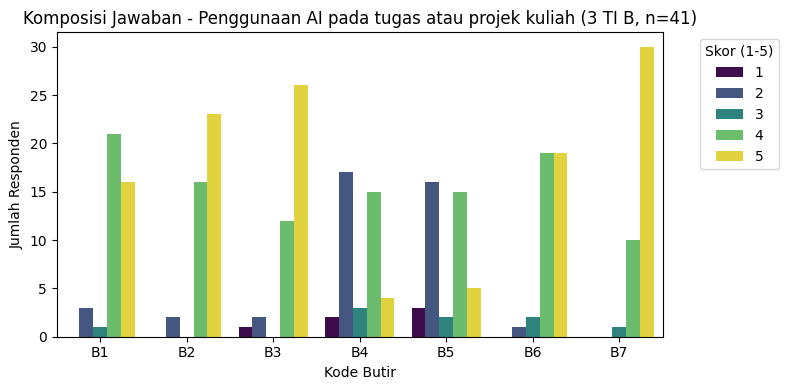

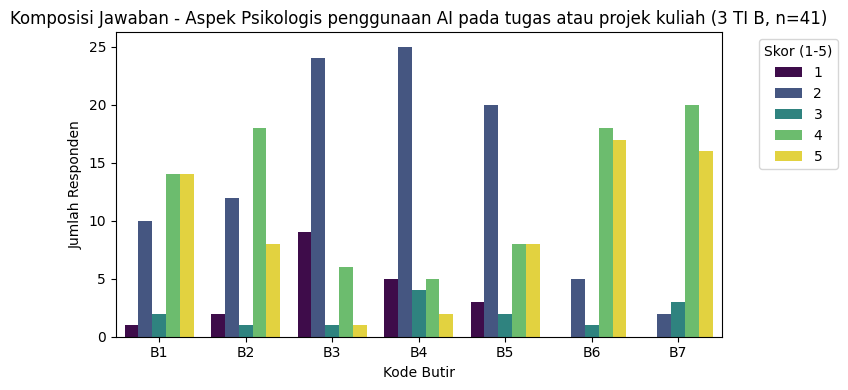

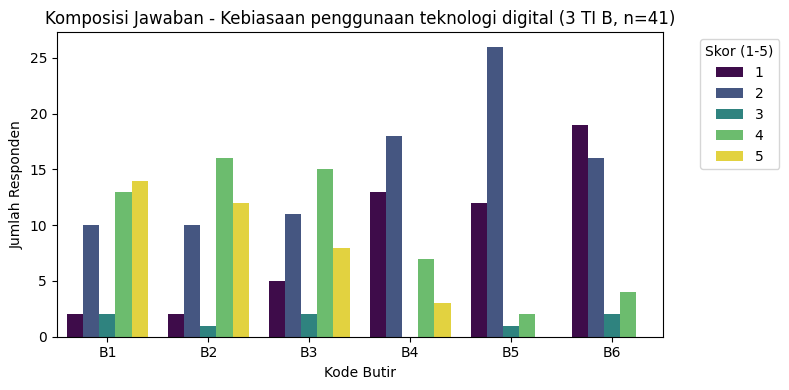

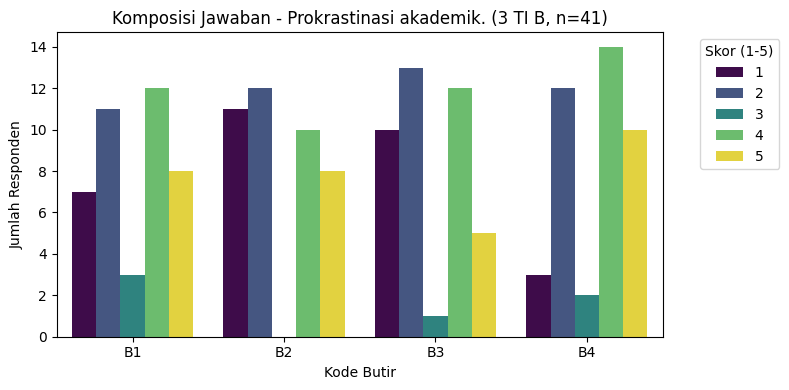

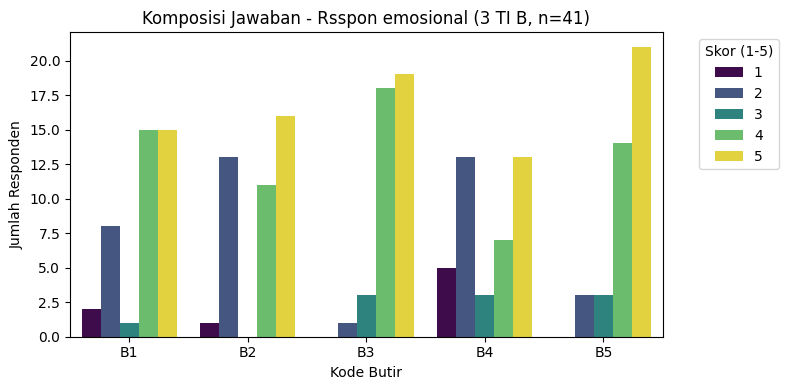


--- STATISTIK DESKRIPTIF SKOR TOTAL PER DIMENSI (3 TI B) ---
                                                     Dimensi   Mean  Std. Deviasi  Skewness  Kurtosis
                 Penggunaan AI pada tugas atau projek kuliah 28.341         3.468    -0.374     0.116
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah 23.024         4.327     0.136     0.984
                      Kebiasaan penggunaan teknologi digital 16.390         3.859     0.019    -0.243
                                     Prokrastinasi akademik. 12.000         4.319    -0.215    -0.729
                                            Rsspon emosional 19.366         3.562    -0.808     0.293

Hasil berhasil disimpan ke 'hasil_uji_validitas_reliabilitas_3TIB.xlsx'.


In [4]:
import re
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# 1. MEMBACA BERKAS EXCEL & MEMFILTER DATA KELAS 3 TI B
# ==============================================================================
excel_file = "Blank Quiz (Responses).xlsx"
xls = pd.ExcelFile(excel_file)
print("Daftar sheet:", xls.sheet_names)

df = pd.read_excel(excel_file, sheet_name=xls.sheet_names[0])

# Filter khusus kelas 3 TI B (mengabaikan spasi berlebih dan huruf kapital)
df_tib = df[
    df["Kelas"]
    .astype(str)
    .str.upper()
    .str.replace(" ", "", regex=False)
    .str.contains("3TIB|TIB", regex=True)
].copy()

# Ambil hanya kolom butir pernyataan kuesioner yang berformat [Pernyataan]
# sehingga kolom demografi / teks bebas / rentang tidak ikut terbaca
question_cols = [c for c in df_tib.columns if "[" in c and "]" in c]
butir = df_tib[question_cols].copy()

# Bersihkan spasi di awal/akhir pada setiap sel jawaban
for col in butir.columns:
    if butir[col].dtype == object:
        butir[col] = butir[col].astype(str).str.strip()

print(f"Jumlah responden (n) 3 TI B : {len(butir)}")
print(f"Jumlah butir pernyataan     : {butir.shape[1]}")
print(f"Data kosong sebelum konversi: {int(butir.isna().sum().sum())}")

# ==============================================================================
# 2. KONVERSI SKALA LIKERT MENJADI ANGKA (1 - 5) TANPA FUTUREWARNING
# ==============================================================================
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
    "Sangat Tidak Setuju": 1,
    "Tidak Setuju": 2,
    "Netral": 3,
    "Setuju": 4,
    "Sangat Setuju": 5,
    "STS": 1,
    "TS": 2,
    "N": 3,
    "S": 4,
    "SS": 5,
}

num = butir.apply(lambda col: pd.to_numeric(col.map(skala), errors="coerce"))
gagal_konversi = int(num.isna().sum().sum())
print(f"Sel gagal dikonversi        : {gagal_konversi}")

if gagal_konversi > 0:
    print("Peringatan: Ada sel yang gagal dikonversi:")
    for col in num.columns:
        mask = num[col].isna()
        if mask.any():
            print(f"  - {col}: {butir.loc[mask, col].unique().tolist()}")

# ==============================================================================
# 3. MENGELOMPOKKAN BUTIR PER DIMENSI
# ==============================================================================
dimensi = {}
for kolom in num.columns:
    match = re.match(r"^(.*?)\s*\[", kolom)
    nama_dimensi = match.group(1).strip() if match else "Tanpa Dimensi"
    dimensi.setdefault(nama_dimensi, []).append(kolom)

print("\nRincian Dimensi dan Jumlah Butir:")
for nama, daftar in dimensi.items():
    print(f"  - {nama}: {len(daftar)} butir")

# ==============================================================================
# 4. UJI VALIDITAS (KORELASI PEARSON BUTIR-TOTAL & CORRECTED R)
# ==============================================================================
n = len(num)
t_crit = stats.t.ppf(0.975, n - 2)
r_tabel = t_crit / np.sqrt((n - 2) + t_crit**2)
print(f"\nn = {n} | df = {n - 2} | r_tabel (alpha = 0,05, dua sisi) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total_dimensi = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total_dimensi)
        total_tanpa_butir = total_dimensi - x[kolom]
        r_koreksi, _ = stats.pearsonr(x[kolom], total_tanpa_butir)
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
print("\n--- TABEL VALIDITAS (3 TI B) ---")
print(tabel_validitas.to_string(index=False))

# ==============================================================================
# 5. UJI RELIABILITAS (CRONBACH'S ALPHA & ALPHA JIKA BUTIR DIHAPUS)
# ==============================================================================
def cronbach_alpha(data_x):
    k = data_x.shape[1]
    if k <= 1:
        return np.nan
    var_butir = data_x.var(ddof=1).sum()
    var_total = data_x.sum(axis=1).var(ddof=1)
    if var_total == 0 or pd.isna(var_total):
        return np.nan
    return (k / (k - 1)) * (1 - (var_butir / var_total))

def kategori_alpha(a):
    if pd.isna(a):
        return "Tidak dapat dihitung"
    if a >= 0.90:
        return "Sangat baik"
    elif a >= 0.80:
        return "Baik"
    elif a >= 0.70:
        return "Reliabel"
    else:
        return "Tidak reliabel"

hasil_reliabilitas = []
alpha_dihapus = []

for nama, daftar in dimensi.items():
    x = num[daftar]
    alpha_val = cronbach_alpha(x)
    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(alpha_val, 3),
        "Kategori": kategori_alpha(alpha_val),
    })
    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_del = cronbach_alpha(x.drop(columns=[kolom]))
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha jika dihapus": round(alpha_del, 3),
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)

print("\n--- TABEL RELIABILITAS (3 TI B) ---")
print(tabel_reliabilitas.to_string(index=False))

print("\n--- TABEL ALPHA JIKA BUTIR DIHAPUS (3 TI B) ---")
print(tabel_alpha_dihapus.to_string(index=False))

# ==============================================================================
# 6. STATISTIK DESKRIPTIF & GRAFIK KOMPOSISI JAWABAN PER DIMENSI
# ==============================================================================
hasil_deskriptif = []
for idx, (nama, daftar) in enumerate(dimensi.items(), 1):
    x = num[daftar]
    tot = x.sum(axis=1)
    mean_val = tot.mean()
    std_val = tot.std(ddof=1)
    skew_val = tot.skew()
    kurt_val = tot.kurtosis()

    hasil_deskriptif.append({
        "Dimensi": nama,
        "Mean": round(mean_val, 3),
        "Std. Deviasi": round(std_val, 3),
        "Skewness": round(skew_val, 3),
        "Kurtosis": round(kurt_val, 3),
    })

    melted = x.melt(var_name="Butir", value_name="Skor")
    col_to_b = {col: f"B{i+1}" for i, col in enumerate(daftar)}
    melted["Kode"] = melted["Butir"].map(col_to_b)

    plt.figure(figsize=(8, 4))
    sns.countplot(data=melted, x="Kode", hue="Skor", palette="viridis")
    plt.title(f"Komposisi Jawaban - {nama} (3 TI B, n={n})")
    plt.xlabel("Kode Butir")
    plt.ylabel("Jumlah Responden")
    plt.legend(title="Skor (1-5)", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

tabel_deskriptif = pd.DataFrame(hasil_deskriptif)
print("\n--- STATISTIK DESKRIPTIF SKOR TOTAL PER DIMENSI (3 TI B) ---")
print(tabel_deskriptif.to_string(index=False))

# ==============================================================================
# 7. EKSPOR HASIL KE BERKAS EXCEL
# ==============================================================================
gabung_validitas = tabel_validitas.merge(
    tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left"
)

output_excel = "hasil_uji_validitas_reliabilitas_3TIB.xlsx"
with pd.ExcelWriter(output_excel, engine="openpyxl") as writer:
    gabung_validitas.to_excel(writer, sheet_name="Validitas_Item", index=False)
    tabel_reliabilitas.to_excel(writer, sheet_name="Reliabilitas_Dimensi", index=False)
    tabel_deskriptif.to_excel(writer, sheet_name="Deskriptif_Dimensi", index=False)

print(f"\nHasil berhasil disimpan ke '{output_excel}'.")